In [ ]:
# Requirements — run this cell first
!pip install transformers==4.36.2 datasets==2.16.1 accelerate==0.25.0 scikit-learn==1.3.2 matplotlib==3.8.2 seaborn==0.13.1 pandas==2.1.4 numpy==1.24.3 torch==2.1.2 --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 117.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [ ]:
import os
import json
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset

In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoConfig,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed,
)
from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
warnings.filterwarnings("ignore")
set_seed(42)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("✅ All imports successful!")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
GPU Memory: 15.6 GB
✅ All imports successful!



# ## 1. Mount Google Drive
# We mount Drive so we can save the trained model checkpoint and all artifacts
# for reuse in Session 2.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Create output directories
DRIVE_BASE = "/content/drive/MyDrive/UnifyComm"
SAVE_DIR = f"{DRIVE_BASE}/models/intent/banking77_checkpoint"
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"✅ Drive mounted. Save directory: {SAVE_DIR}")

Mounted at /content/drive
✅ Drive mounted. Save directory: /content/drive/MyDrive/UnifyComm/models/intent/banking77_checkpoint


# ## 2. Load and Explore Banking77 Dataset
# Banking77 is a single-domain intent detection dataset consisting of 13,083
# customer service queries across 77 fine-grained intents related to banking.
# It uses the standard train/test split provided by the dataset authors.


In [ ]:
print("📥 Loading Banking77 dataset from HuggingFace...")
dataset = load_dataset("banking77")
print(f"\n📊 Dataset structure:")
print(dataset)
print(f"\n  Train samples: {len(dataset['train']):,}")
print(f"  Test samples:  {len(dataset['test']):,}")
print(f"  Number of intents: {dataset['train'].features['label'].num_classes}")

# Get the label names
label_names = dataset['train'].features['label'].names
print(f"\n📋 First 10 intent labels:")
for i, name in enumerate(label_names[:10]):
    print(f"  {i:2d}. {name}")
print(f"  ... ({len(label_names) - 10} more)")

📥 Loading Banking77 dataset from HuggingFace...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/298k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/93.9k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]


📊 Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})

  Train samples: 10,003
  Test samples:  3,080
  Number of intents: 77

📋 First 10 intent labels:
   0. activate_my_card
   1. age_limit
   2. apple_pay_or_google_pay
   3. atm_support
   4. automatic_top_up
   5. balance_not_updated_after_bank_transfer
   6. balance_not_updated_after_cheque_or_cash_deposit
   7. beneficiary_not_allowed
   8. cancel_transfer
   9. card_about_to_expire
  ... (67 more)


# ### Class Distribution
# Visualize how many examples exist per intent class. Banking77 is relatively
# balanced, but some intents may have slightly more examples than others.

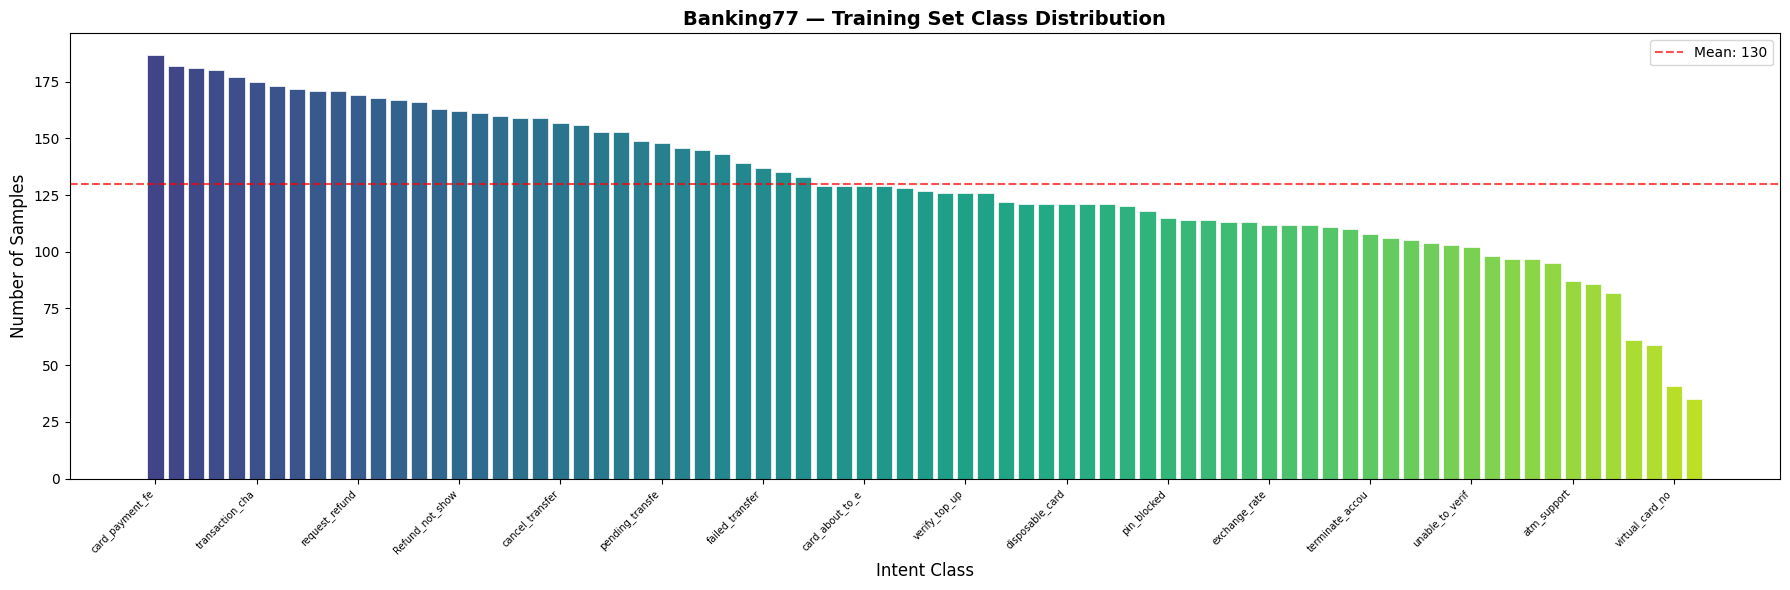


📊 Distribution stats:
  Min samples per class: 35
  Max samples per class: 187
  Mean samples per class: 129.9
  Std dev: 32.7


In [ ]:
train_labels = dataset['train']['label']
label_counts = Counter(train_labels)
sorted_counts = sorted(label_counts.items(), key=lambda x: x[1], reverse=True)

fig, ax = plt.subplots(figsize=(18, 6))
indices = range(len(sorted_counts))
counts = [c for _, c in sorted_counts]
names = [label_names[idx] for idx, _ in sorted_counts]

bars = ax.bar(indices, counts, color=plt.cm.viridis(np.linspace(0.2, 0.9, len(sorted_counts))),
              edgecolor='white', linewidth=0.5)
ax.set_xlabel("Intent Class", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)
ax.set_title("Banking77 — Training Set Class Distribution", fontsize=14, fontweight='bold')
ax.set_xticks(indices[::5])
ax.set_xticklabels([names[i][:15] for i in range(0, len(names), 5)], rotation=45, ha='right', fontsize=7)
ax.axhline(y=np.mean(counts), color='red', linestyle='--', alpha=0.7, label=f'Mean: {np.mean(counts):.0f}')
ax.legend()
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/class_distribution_banking77.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📊 Distribution stats:")
print(f"  Min samples per class: {min(counts)}")
print(f"  Max samples per class: {max(counts)}")
print(f"  Mean samples per class: {np.mean(counts):.1f}")
print(f"  Std dev: {np.std(counts):.1f}")

# ### Random Sample Examples
# Print 3 random examples from each split to understand the data format,
# message style, and label assignments.

In [ ]:
print("=" * 70)
print("📝 RANDOM EXAMPLES FROM EACH SPLIT")
print("=" * 70)
for split_name in ['train', 'test']:
    print(f"\n--- {split_name.upper()} SET ---")
    indices = random.sample(range(len(dataset[split_name])), 3)
    for i, idx in enumerate(indices, 1):
        example = dataset[split_name][idx]
        intent = label_names[example['label']]
        print(f"\n  Example {i}:")
        print(f"    Text:   \"{example['text']}\"")
        print(f"    Intent: {intent} (id={example['label']})")

📝 RANDOM EXAMPLES FROM EACH SPLIT

--- TRAIN SET ---

  Example 1:
    Text:   "Can you tell me the cost of a transfer?"
    Intent: top_up_by_bank_transfer_charge (id=56)

  Example 2:
    Text:   "I think something went wrong with my exchange between Russian Ruble and UK pounds. I was overcharged during the swap."
    Intent: card_payment_wrong_exchange_rate (id=17)

  Example 3:
    Text:   "I see some transactions that I don't recognize.  I think someone stole my details."
    Intent: compromised_card (id=22)

--- TEST SET ---

  Example 1:
    Text:   "My top-up showed as complete, but it's no longer there! What's going on here?"
    Intent: top_up_reverted (id=61)

  Example 2:
    Text:   "Is my currency okay to add money with?"
    Intent: supported_cards_and_currencies (id=54)

  Example 3:
    Text:   "I couldn't use my contactless this morning, it wasn't accepted."
    Intent: contactless_not_working (id=23)


# ## 3. Preprocessing + Label Mapping
# We clean the text (lowercase, remove special chars), create label mappings
# (label2id/id2label), and tokenize everything using the MiniLM tokenizer.
# **Estimated time: ~1 minute**

In [ ]:
import re

def clean_text(text):
    """
    Clean customer message text:
    - Lowercase everything for consistency
    - Remove special characters but keep basic punctuation (.,!?')
      since punctuation carries sentiment/intent cues
    - Collapse multiple whitespace into single space
    """
    text = text.lower().strip()
    # Keep letters, digits, spaces, and common punctuation
    text = re.sub(r'[^a-z0-9\s\.\,\!\?\'\-]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Test the cleaning function
test_texts = [
    "I CAN'T access my account!!!",
    "What's the fee for $$ wire transfer??",
    "my card  was   stolen #help @bank"
]
print("🧹 Text cleaning examples:")
for t in test_texts:
    print(f"  Original: \"{t}\"")
    print(f"  Cleaned:  \"{clean_text(t)}\"")
    print()

🧹 Text cleaning examples:
  Original: "I CAN'T access my account!!!"
  Cleaned:  "i can't access my account!!!"

  Original: "What's the fee for $$ wire transfer??"
  Cleaned:  "what's the fee for wire transfer??"

  Original: "my card  was   stolen #help @bank"
  Cleaned:  "my card was stolen help bank"



In [ ]:
# Create label mappings
label2id = {name: idx for idx, name in enumerate(label_names)}
id2label = {idx: name for idx, name in enumerate(label_names)}
num_labels = len(label_names)

print(f"✅ Label mappings created: {num_labels} classes")

# Save label mappings to Drive
with open(f"{SAVE_DIR}/label2id.json", 'w') as f:
    json.dump(label2id, f, indent=2)
with open(f"{SAVE_DIR}/id2label.json", 'w') as f:
    json.dump(id2label, f, indent=2)
print(f"💾 Saved label2id.json and id2label.json to {SAVE_DIR}")

✅ Label mappings created: 77 classes
💾 Saved label2id.json and id2label.json to /content/drive/MyDrive/UnifyComm/models/intent/banking77_checkpoint


In [ ]:
# Tokenization
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
MAX_LENGTH = 64

print(f"📦 Loading tokenizer: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Apply text cleaning to dataset
def preprocess_and_tokenize(examples):
    """Clean text and tokenize in one step."""
    cleaned_texts = [clean_text(t) for t in examples['text']]
    tokenized = tokenizer(
        cleaned_texts,
        padding='max_length',
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors=None  # Return lists for dataset mapping
    )
    tokenized['labels'] = examples['label']
    return tokenized

print("🔧 Tokenizing dataset...")
tokenized_dataset = dataset.map(
    preprocess_and_tokenize,
    batched=True,
    batch_size=256,
    remove_columns=dataset['train'].column_names,
    desc="Tokenizing"
)
tokenized_dataset.set_format("torch")

print(f"\n✅ Tokenization complete!")
print(f"  Train features: {tokenized_dataset['train'].column_names}")
print(f"  Sample input_ids shape: {tokenized_dataset['train'][0]['input_ids'].shape}")

📦 Loading tokenizer: sentence-transformers/all-MiniLM-L6-v2


config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

🔧 Tokenizing dataset...


Tokenizing:   0%|          | 0/10003 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/3080 [00:00<?, ? examples/s]


✅ Tokenization complete!
  Train features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']
  Sample input_ids shape: torch.Size([64])


# ## 4. Model Setup
# We load the pretrained MiniLM-L6-v2 encoder and add a classification head
# (dropout + linear layer mapping from 384-dim embeddings to 77 classes).
# This architecture pools the token-level representations using mean pooling
# before classification.
# **Estimated time: ~30 seconds**

In [ ]:
from transformers.modeling_outputs import SequenceClassifierOutput

class IntentClassifier(nn.Module):
    """
    Sentence-transformer based intent classifier.

    Architecture:
    1. MiniLM-L6-v2 encoder (6 layers, 384-dim)
    2. Mean pooling over token embeddings
    3. Dropout (0.1) for regularization
    4. Linear classification head → 77 classes

    We use nn.Module (NOT PreTrainedModel) because newer transformers
    versions break when PreTrainedModel is subclassed inside Colab cells.
    We use mean pooling instead of [CLS] token because sentence-transformers
    are trained with mean pooling and produce better sentence representations.
    """
    def __init__(self, model_name_or_encoder, num_labels, dropout_rate=0.1):
        super().__init__()
        # Accept either a model name string or a pre-built encoder module
        if isinstance(model_name_or_encoder, str):
            self.encoder = AutoModel.from_pretrained(model_name_or_encoder)
        else:
            self.encoder = model_name_or_encoder
        self.hidden_size = self.encoder.config.hidden_size  # 384 for MiniLM
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(self.hidden_size, num_labels)
        self.num_labels = num_labels
        self.config = self.encoder.config  # Keep config reference for Trainer

    def mean_pooling(self, model_output, attention_mask):
        """Mean pool token embeddings, respecting attention mask."""
        token_embeddings = model_output.last_hidden_state
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(
            input_mask_expanded.sum(1), min=1e-9
        )

    def forward(self, input_ids, attention_mask=None, labels=None, **kwargs):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.mean_pooling(outputs, attention_mask)
        pooled = self.dropout(pooled)
        logits = self.classifier(pooled)

        loss = None
        if labels is not None:
            loss_fn = nn.CrossEntropyLoss()
            loss = loss_fn(logits, labels)

        # Return SequenceClassifierOutput so HuggingFace Trainer can read .loss and .logits
        return SequenceClassifierOutput(loss=loss, logits=logits)

In [ ]:
# Initialize model
print("🔧 Initializing model...")

# Create model directly with pretrained encoder — no PreTrainedModel needed
model = IntentClassifier(
    model_name_or_encoder=MODEL_NAME,
    num_labels=num_labels,
    dropout_rate=0.1
)

# Move to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Print model summary
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
encoder_params = sum(p.numel() for p in model.encoder.parameters())
classifier_params = sum(p.numel() for p in model.classifier.parameters())

print(f"\n📊 Model Parameter Count:")
print(f"  Total parameters:      {total_params:>12,}")
print(f"  Trainable parameters:  {trainable_params:>12,}")
print(f"  Encoder parameters:    {encoder_params:>12,}")
print(f"  Classifier parameters: {classifier_params:>12,}")
print(f"  Device: {device}")
print("✅ Model ready!")

🔧 Initializing model...


model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



📊 Model Parameter Count:
  Total parameters:        22,742,861
  Trainable parameters:    22,742,861
  Encoder parameters:      22,713,216
  Classifier parameters:       29,645
  Device: cuda
✅ Model ready!


# ## 5. Training
# We train using HuggingFace Trainer with the following strategy:
# - **5 epochs** with early stopping (patience=2) based on validation accuracy
# - **FP16 mixed precision** for ~2x speedup on T4 GPU
# - **Warmup** for 100 steps then linear decay
# - **Best model checkpoint** saved based on validation accuracy
# **Estimated time: ~15-20 minutes on T4**

In [ ]:
def compute_metrics(eval_pred):
    """Compute accuracy and F1 scores during training."""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(labels, predictions, average='macro')
    weighted_f1 = f1_score(labels, predictions, average='weighted')
    return {
        'accuracy': accuracy,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
    }

In [ ]:
# Training Arguments
OUTPUT_DIR = "/content/banking77_training"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,              # Larger for faster eval
    learning_rate=2e-5,
    warmup_steps=100,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    fp16=True,                                  # Mixed precision for T4
    dataloader_num_workers=2,
    seed=42,
    report_to="none",                           # No W&B/MLflow
    save_total_limit=2,                         # Keep only 2 best checkpoints
    remove_unused_columns=False,
)

# Create Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset['train'],
    eval_dataset=tokenized_dataset['test'],
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print("🚀 Starting training...")
print(f"  Epochs: {training_args.num_train_epochs}")
print(f"  Batch size: {training_args.per_device_train_batch_size}")
print(f"  Learning rate: {training_args.learning_rate}")
print(f"  FP16: {training_args.fp16}")
print(f"  Total training steps: ~{len(tokenized_dataset['train']) // 32 * 5}")


🚀 Starting training...
  Epochs: 5
  Batch size: 32
  Learning rate: 2e-05
  FP16: True
  Total training steps: ~1560


In [ ]:
# Train!
train_result = trainer.train()

# Print training summary
print("\n" + "=" * 50)
print("✅ TRAINING COMPLETE!")
print("=" * 50)
print(f"  Total training time: {train_result.metrics['train_runtime']:.1f}s")
print(f"  Samples/second: {train_result.metrics['train_samples_per_second']:.1f}")
print(f"  Final training loss: {train_result.metrics['train_loss']:.4f}")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,2.640912,2.206187,0.657792,0.616619,0.616619
2,1.651263,1.343282,0.787013,0.768420,0.768420
3,1.236015,1.000106,0.828571,0.816796,0.816796
4,1.001722,0.850402,0.850000,0.841941,0.841941
5,0.937725,0.805221,0.856169,0.849133,0.849133



✅ TRAINING COMPLETE!
  Total training time: 70.5s
  Samples/second: 709.6
  Final training loss: 1.7537


# ## 6. Evaluation + Plots
# Generate comprehensive evaluation metrics and visualizations:
# 1. Training/validation loss curves
# 2. Accuracy per epoch
# 3. Full classification report (77 classes)
# 4. Confusion matrix for top 15 intents
# 5. Summary metrics table
# 6. Inference speed benchmark
# **Estimated time: ~3 minutes**

In [ ]:
log_history = trainer.state.log_history

# Parse training and eval metrics from log history
train_losses = []
eval_losses = []
eval_accuracies = []
eval_macro_f1s = []
eval_weighted_f1s = []
epochs_list = []

for entry in log_history:
    if 'loss' in entry and 'eval_loss' not in entry:
        train_losses.append({'step': entry['step'], 'loss': entry['loss']})
    if 'eval_loss' in entry:
        eval_losses.append(entry['eval_loss'])
        eval_accuracies.append(entry.get('eval_accuracy', 0))
        eval_macro_f1s.append(entry.get('eval_macro_f1', 0))
        eval_weighted_f1s.append(entry.get('eval_weighted_f1', 0))
        epochs_list.append(entry.get('epoch', len(eval_losses)))

# Save training stats as CSV
stats_df = pd.DataFrame({
    'epoch': epochs_list[:len(eval_losses)],
    'eval_loss': eval_losses,
    'eval_accuracy': eval_accuracies,
    'eval_macro_f1': eval_macro_f1s,
    'eval_weighted_f1': eval_weighted_f1s,
})
stats_df.to_csv(f"{SAVE_DIR}/training_stats.csv", index=False)
print("💾 training_stats.csv saved!")


💾 training_stats.csv saved!


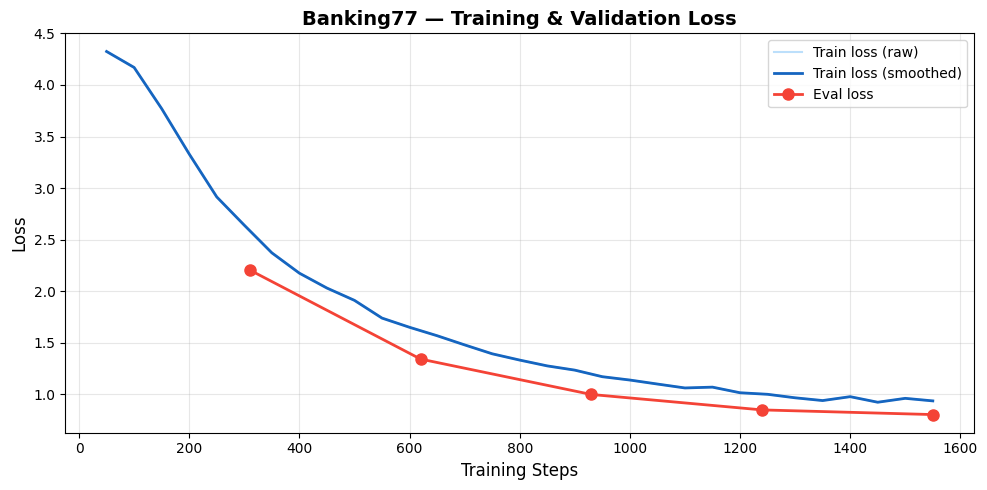

💾 loss_curve_banking77.png saved!


In [ ]:
# --- PLOT 1: Loss Curves ---
fig, ax = plt.subplots(figsize=(10, 5))

# Training loss (per step, smoothed)
if train_losses:
    steps = [d['step'] for d in train_losses]
    losses = [d['loss'] for d in train_losses]
    ax.plot(steps, losses, alpha=0.3, color='#2196F3', label='Train loss (raw)')
    # Smoothed version using rolling average
    window = max(1, len(losses) // 20)
    if len(losses) > window:
        smoothed = pd.Series(losses).rolling(window=window, min_periods=1).mean()
        ax.plot(steps, smoothed, color='#1565C0', linewidth=2, label='Train loss (smoothed)')

# Eval loss (per epoch)
if eval_losses:
    # Map epochs to approximate step positions
    total_steps = steps[-1] if steps else 1
    epoch_steps = [int(e / max(epochs_list) * total_steps) for e in epochs_list[:len(eval_losses)]]
    ax.plot(epoch_steps, eval_losses, 'o-', color='#F44336', linewidth=2,
            markersize=8, label='Eval loss')

ax.set_xlabel("Training Steps", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_title("Banking77 — Training & Validation Loss", fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/loss_curve_banking77.png", dpi=150, bbox_inches='tight')
plt.show()
print("💾 loss_curve_banking77.png saved!")

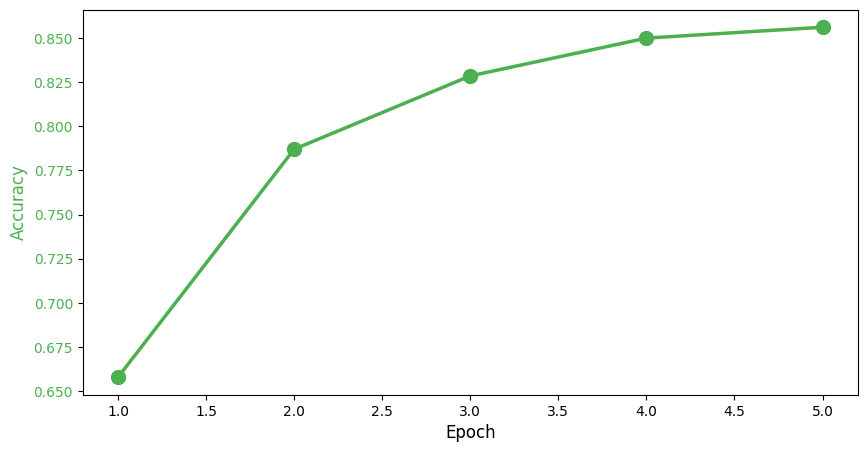

In [ ]:
# --- PLOT 2: Accuracy Per Epoch ---
fig, ax1 = plt.subplots(figsize=(10, 5))

epoch_range = list(range(1, len(eval_accuracies) + 1))
ax1.plot(epoch_range, eval_accuracies, 'o-', color='#4CAF50', linewidth=2.5,
         markersize=10, label='Accuracy', zorder=5)
ax1.set_xlabel("Epoch", fontsize=12)
ax1.set_ylabel("Accuracy", fontsize=12, color='#4CAF50')
ax1.tick_params(axis='y', labelcolor='#4CAF50')


In [ ]:
# Add F1 scores on secondary axis
ax2 = ax1.twinx()
ax2.plot(epoch_range, eval_macro_f1s, 's--', color='#FF9800', linewidth=2,
         markersize=8, label='Macro F1')
ax2.plot(epoch_range, eval_weighted_f1s, '^--', color='#9C27B0', linewidth=2,
         markersize=8, label='Weighted F1')
ax2.set_ylabel("F1 Score", fontsize=12, color='#FF9800')
ax2.tick_params(axis='y', labelcolor='#FF9800')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right', fontsize=10)
best_epoch = np.argmax(eval_accuracies) + 1
best_acc = max(eval_accuracies)
ax1.annotate(f'{best_acc:.4f}', xy=(best_epoch, best_acc),
             xytext=(best_epoch + 0.3, best_acc - 0.02),
             arrowprops=dict(arrowstyle='->', color='gray'),
             fontsize=11, fontweight='bold', color='#2E7D32')

ax1.set_title("Banking77 — Metrics Per Epoch", fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_xticks(epoch_range)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/accuracy_banking77.png", dpi=150, bbox_inches='tight')
plt.show()
print("💾 accuracy_banking77.png saved!")

<Figure size 640x480 with 0 Axes>

💾 accuracy_banking77.png saved!


In [ ]:
print("🔍 Running final evaluation on test set...")
predictions_output = trainer.predict(tokenized_dataset['test'])
predictions = np.argmax(predictions_output.predictions, axis=-1)
true_labels = np.array(dataset['test']['label'])

🔍 Running final evaluation on test set...


In [ ]:
print("\n" + "=" * 80)
print("📊 CLASSIFICATION REPORT — ALL 77 INTENTS")
print("=" * 80)
report = classification_report(
    true_labels, predictions,
    target_names=label_names,
    digits=4,
    output_dict=True
)
report_str = classification_report(
    true_labels, predictions,
    target_names=label_names,
    digits=4
)
print(report_str)


📊 CLASSIFICATION REPORT — ALL 77 INTENTS
                                                  precision    recall  f1-score   support

                                activate_my_card     0.9744    0.9500    0.9620        40
                                       age_limit     0.9756    1.0000    0.9877        40
                         apple_pay_or_google_pay     0.9091    1.0000    0.9524        40
                                     atm_support     0.9744    0.9500    0.9620        40
                                automatic_top_up     1.0000    0.9000    0.9474        40
         balance_not_updated_after_bank_transfer     0.7143    0.7500    0.7317        40
balance_not_updated_after_cheque_or_cash_deposit     0.9512    0.9750    0.9630        40
                         beneficiary_not_allowed     0.9333    0.7000    0.8000        40
                                 cancel_transfer     0.9211    0.8750    0.8974        40
                            card_about_to_expire     1.00

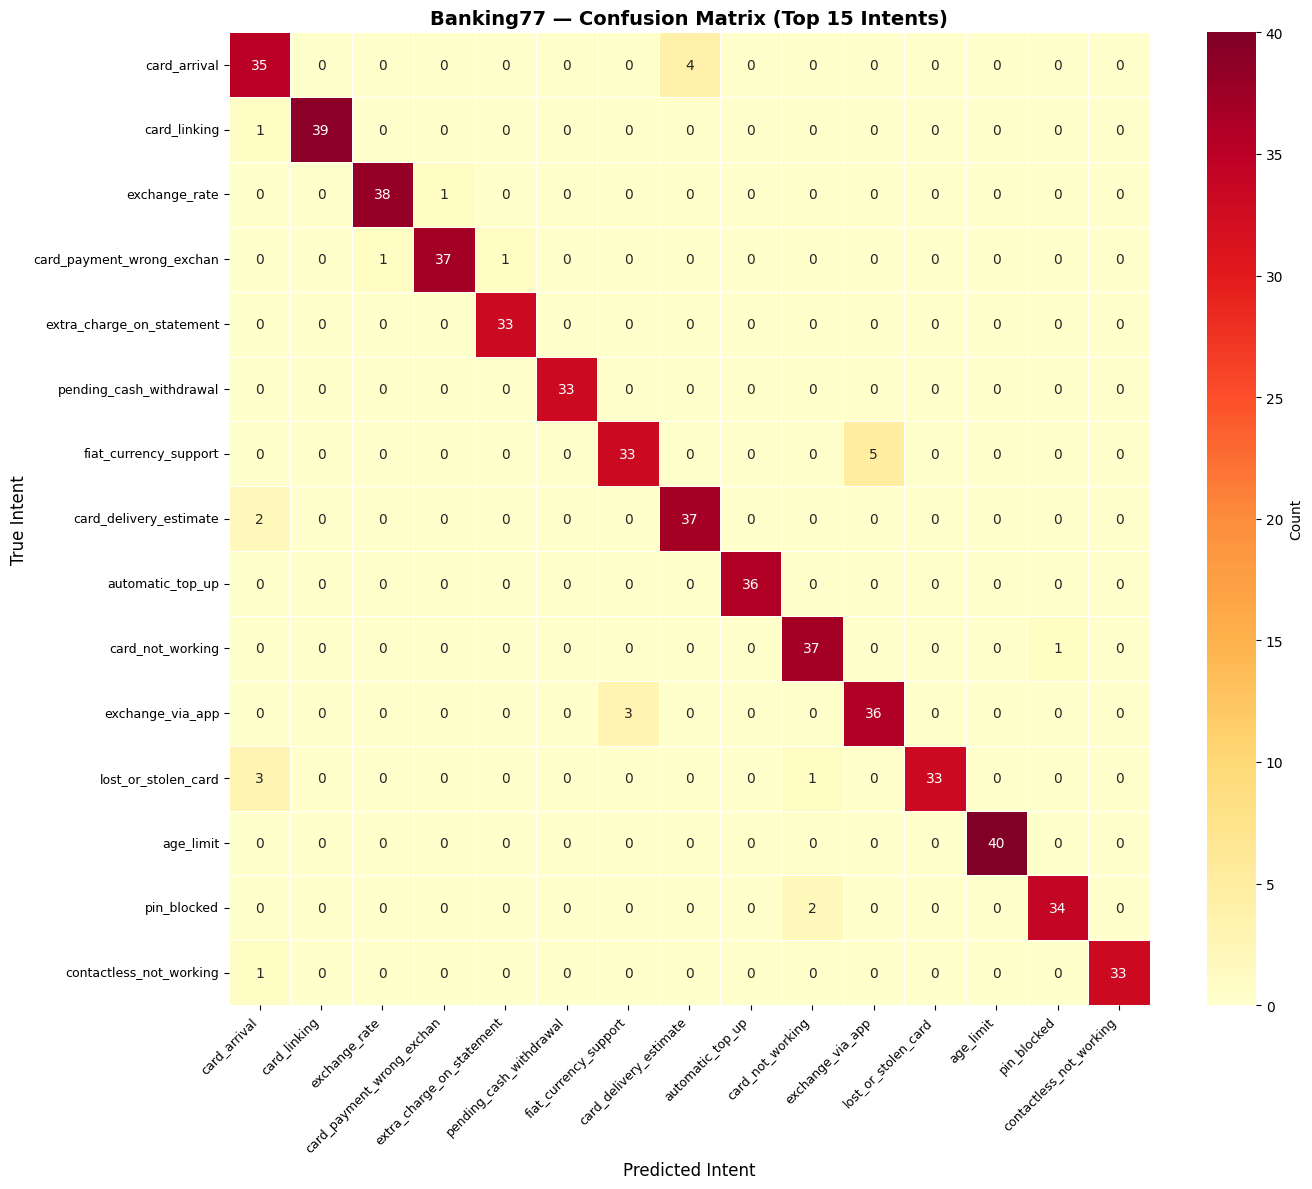

💾 confusion_matrix_banking77.png saved!


In [ ]:
 # --- PLOT 3: Confusion Matrix (Top 15 Intents) ---
# Select the 15 most frequent intents for a readable confusion matrix
test_label_counts = Counter(true_labels)
top_15_labels = [label_id for label_id, _ in test_label_counts.most_common(15)]
top_15_names = [label_names[i] for i in top_15_labels]

# Filter predictions for top 15
mask = np.isin(true_labels, top_15_labels)
filtered_true = true_labels[mask]
filtered_pred = predictions[mask]

# Remap labels to 0-14 for the confusion matrix
label_remap = {old: new for new, old in enumerate(top_15_labels)}
remapped_true = np.array([label_remap[l] for l in filtered_true])
remapped_pred = np.array([label_remap.get(l, -1) for l in filtered_pred])
# Handle predictions outside top 15
valid_mask = remapped_pred >= 0
remapped_true = remapped_true[valid_mask]
remapped_pred = remapped_pred[valid_mask]

cm = confusion_matrix(remapped_true, remapped_pred, labels=list(range(15)))

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd',
            xticklabels=[n[:25] for n in top_15_names],
            yticklabels=[n[:25] for n in top_15_names],
            ax=ax, linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Count'})
ax.set_xlabel("Predicted Intent", fontsize=12)
ax.set_ylabel("True Intent", fontsize=12)
ax.set_title("Banking77 — Confusion Matrix (Top 15 Intents)", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/confusion_matrix_banking77.png", dpi=150, bbox_inches='tight')
plt.show()
print("💾 confusion_matrix_banking77.png saved!")

In [ ]:
# --- Overall Metrics Table ---
overall_accuracy = accuracy_score(true_labels, predictions)
macro_f1 = f1_score(true_labels, predictions, average='macro')
weighted_f1 = f1_score(true_labels, predictions, average='weighted')

print("\n" + "=" * 60)
print("📊 OVERALL METRICS SUMMARY")
print("=" * 60)
metrics_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro F1', 'Weighted F1'],
    'Score': [f'{overall_accuracy:.4f}', f'{macro_f1:.4f}', f'{weighted_f1:.4f}']
})
print(metrics_table.to_string(index=False))

# Per-class precision, recall, F1
print("\n📊 PER-CLASS METRICS (sorted by F1):")
per_class_metrics = []
for label_name in label_names:
    if label_name in report:
        m = report[label_name]
        per_class_metrics.append({
            'Intent': label_name,
            'Precision': f"{m['precision']:.4f}",
            'Recall': f"{m['recall']:.4f}",
            'F1-Score': f"{m['f1-score']:.4f}",
            'Support': int(m['support'])
        })

per_class_df = pd.DataFrame(per_class_metrics)
per_class_df = per_class_df.sort_values('F1-Score', ascending=False)
print(per_class_df.to_string(index=False))



📊 OVERALL METRICS SUMMARY
     Metric  Score
   Accuracy 0.8562
   Macro F1 0.8491
Weighted F1 0.8491

📊 PER-CLASS METRICS (sorted by F1):
                                          Intent Precision Recall F1-Score  Support
                                   verify_top_up    0.9756 1.0000   0.9877       40
                          verify_source_of_funds    0.9756 1.0000   0.9877       40
                              passcode_forgotten    0.9756 1.0000   0.9877       40
                                       age_limit    0.9756 1.0000   0.9877       40
                            card_about_to_expire    1.0000 0.9750   0.9873       40
                           edit_personal_details    0.9524 1.0000   0.9756       40
                               get_physical_card    0.9302 1.0000   0.9639       40
                                   top_up_limits    0.9302 1.0000   0.9639       40
balance_not_updated_after_cheque_or_cash_deposit    0.9512 0.9750   0.9630       40
                    

In [ ]:
# --- Inference Speed Benchmark ---
print("\n⏱️ Running inference speed benchmark...")
model.eval()

# Warm up GPU
sample_input = tokenized_dataset['test'][0]
dummy_ids = sample_input['input_ids'].unsqueeze(0).to(device)
dummy_mask = sample_input['attention_mask'].unsqueeze(0).to(device)
for _ in range(10):
    with torch.no_grad():
        _ = model(input_ids=dummy_ids, attention_mask=dummy_mask)
latencies = []
for i in range(100):
    sample = tokenized_dataset['test'][i % len(tokenized_dataset['test'])]
    input_ids = sample['input_ids'].unsqueeze(0).to(device)
    attention_mask = sample['attention_mask'].unsqueeze(0).to(device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.no_grad():
        _ = model(input_ids=input_ids, attention_mask=attention_mask)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    end = time.perf_counter()

    latencies.append((end - start) * 1000)  # Convert to ms

avg_latency = np.mean(latencies)
p50_latency = np.percentile(latencies, 50)
p95_latency = np.percentile(latencies, 95)
p99_latency = np.percentile(latencies, 99)

print(f"\n📊 Inference Speed (single message):")
print(f"  Average:  {avg_latency:.2f} ms")
print(f"  Median:   {p50_latency:.2f} ms")
print(f"  P95:      {p95_latency:.2f} ms")
print(f"  P99:      {p99_latency:.2f} ms")
print(f"  Throughput: ~{1000/avg_latency:.0f} messages/sec")


⏱️ Running inference speed benchmark...

📊 Inference Speed (single message):
  Average:  18.64 ms
  Median:   18.86 ms
  P95:      34.01 ms
  P99:      40.30 ms
  Throughput: ~54 messages/sec


In [ ]:
print("💾 Saving model checkpoint to Google Drive...")

# Save full model state dict (encoder + classifier) using torch.save
# We DON'T use save_pretrained since our model is nn.Module, not PreTrainedModel
torch.save(model.state_dict(), f"{SAVE_DIR}/pytorch_model.bin")
print(f"  ✅ Model weights saved (pytorch_model.bin)")

# Save the encoder config so we can rebuild the architecture later
model.encoder.config.save_pretrained(SAVE_DIR)
print(f"  ✅ Encoder config saved (config.json)")

# Save tokenizer
tokenizer.save_pretrained(SAVE_DIR)
print(f"  ✅ Tokenizer saved")

# Save model architecture metadata (needed to rebuild in Session 2)
model_meta = {
    'model_name': MODEL_NAME,
    'num_labels': num_labels,
    'hidden_size': model.hidden_size,
    'dropout_rate': 0.1,
    'max_length': MAX_LENGTH,
}
with open(f"{SAVE_DIR}/model_meta.json", 'w') as f:
    json.dump(model_meta, f, indent=2)
print(f"  ✅ model_meta.json saved")

# Save final metrics
final_metrics = {
    'accuracy': float(overall_accuracy),
    'macro_f1': float(macro_f1),
    'weighted_f1': float(weighted_f1),
    'inference_avg_ms': float(avg_latency),
    'inference_p95_ms': float(p95_latency),
    'num_classes': num_labels,
    'model_name': MODEL_NAME,
    'dataset': 'banking77',
    'epochs_trained': len(eval_accuracies),
    'best_epoch': int(best_epoch),
}
with open(f"{SAVE_DIR}/final_metrics.json", 'w') as f:
    json.dump(final_metrics, f, indent=2)
print(f"  ✅ final_metrics.json saved")

# Verify saved files

💾 Saving model checkpoint to Google Drive...
  ✅ Model weights saved (pytorch_model.bin)
  ✅ Encoder config saved (config.json)
  ✅ Tokenizer saved
  ✅ model_meta.json saved
  ✅ final_metrics.json saved
